In [2]:
import numpy as np
import pandas as pd
import re
import string
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score , precision_score, recall_score, f1_score, classification_report, confusion_matrix, roc_auc_score, roc_curve)

In [3]:
data = pd.read_csv(r"Downloads/Amazon_Reviews (1).csv")
data

,Reviewer Name,Profile Link,Country,Review Count,Review Date,Rating,Review Title,Review Text,Date of Experience
0,Eugene ath,/users/66e8185ff1598352d6b3701a,US,1 review,2024-09-16T13:44:26.000Z,Rated 1 out of 5 stars,A Store That Doesn't Want to Sell Anything,"I registered on the website, tried to order a ...","September 16, 2024"
1,Daniel ohalloran,/users/5d75e460200c1f6a6373648c,GB,9 reviews,2024-09-16T18:26:46.000Z,Rated 1 out of 5 stars,Had multiple orders one turned up and…,Had multiple orders one turned up and driver h...,"September 16, 2024"
2,p fisher,/users/546cfcf1000064000197b88f,GB,90 reviews,2024-09-16T21:47:39.000Z,Rated 1 out of 5 stars,I informed these reprobates,I informed these reprobates that I WOULD NOT B...,"September 16, 2024"
3,Greg Dunn,/users/62c35cdbacc0ea0012ccaffa,AU,5 reviews,2024-09-17T07:15:49.000Z,Rated 1 out of 5 stars,Advertise one price then increase it on website,I have bought from Amazon before and no proble...,"September 17, 2024"
4,Sheila Hannah,/users/5ddbe429478d88251550610e,GB,8 reviews,2024-09-16T18:37:17.000Z,Rated 1 out of 5 stars,If I could give a lower rate I would,If I could give a lower rate I would! I cancel...,"September 16, 2024"
...,...,...,...,...,...,...,...,...,...
21209,Anders T,/users/47bd4ffe0000640001001044,DK,1 review,2009-03-22T13:14:12.000Z,Rated 5 out of 5 stars,Fast!!,"I have had perfect order fulfillment, and fast...","March 22, 2009"
21210,David E,/users/495bbbc0000064000100a972,US,2 reviews,2008-12-31T18:57:31.000Z,Rated 5 out of 5 stars,Consistently Excellent,"I have had perfect order fulfillment, and fast...","December 31, 2008"
21211,Joseph Harding,/users/48cfacbf0000640001005d04,GB,3 reviews,2008-09-16T13:05:05.000Z,Rated 3 out of 5 stars,Good prices but delivery can take time :(,I always find myself going back to amazon beco...,"September 16, 2008"
21212,Mads Dørup,/users/474aaec70000640001000a44,DK,82 reviews,2008-04-28T11:09:05.000Z,Rated 5 out of 5 stars,World-class online shopping,I have placed an abundance of orders with Amaz...,"April 28, 2008"


In [4]:
data.head()

,Reviewer Name,Profile Link,Country,Review Count,Review Date,Rating,Review Title,Review Text,Date of Experience
0,Eugene ath,/users/66e8185ff1598352d6b3701a,US,1 review,2024-09-16T13:44:26.000Z,Rated 1 out of 5 stars,A Store That Doesn't Want to Sell Anything,"I registered on the website, tried to order a ...","September 16, 2024"
1,Daniel ohalloran,/users/5d75e460200c1f6a6373648c,GB,9 reviews,2024-09-16T18:26:46.000Z,Rated 1 out of 5 stars,Had multiple orders one turned up and…,Had multiple orders one turned up and driver h...,"September 16, 2024"
2,p fisher,/users/546cfcf1000064000197b88f,GB,90 reviews,2024-09-16T21:47:39.000Z,Rated 1 out of 5 stars,I informed these reprobates,I informed these reprobates that I WOULD NOT B...,"September 16, 2024"
3,Greg Dunn,/users/62c35cdbacc0ea0012ccaffa,AU,5 reviews,2024-09-17T07:15:49.000Z,Rated 1 out of 5 stars,Advertise one price then increase it on website,I have bought from Amazon before and no proble...,"September 17, 2024"
4,Sheila Hannah,/users/5ddbe429478d88251550610e,GB,8 reviews,2024-09-16T18:37:17.000Z,Rated 1 out of 5 stars,If I could give a lower rate I would,If I could give a lower rate I would! I cancel...,"September 16, 2024"


In [5]:
data.head()

,Reviewer Name,Profile Link,Country,Review Count,Review Date,Rating,Review Title,Review Text,Date of Experience
0,Eugene ath,/users/66e8185ff1598352d6b3701a,US,1 review,2024-09-16T13:44:26.000Z,Rated 1 out of 5 stars,A Store That Doesn't Want to Sell Anything,"I registered on the website, tried to order a ...","September 16, 2024"
1,Daniel ohalloran,/users/5d75e460200c1f6a6373648c,GB,9 reviews,2024-09-16T18:26:46.000Z,Rated 1 out of 5 stars,Had multiple orders one turned up and…,Had multiple orders one turned up and driver h...,"September 16, 2024"
2,p fisher,/users/546cfcf1000064000197b88f,GB,90 reviews,2024-09-16T21:47:39.000Z,Rated 1 out of 5 stars,I informed these reprobates,I informed these reprobates that I WOULD NOT B...,"September 16, 2024"
3,Greg Dunn,/users/62c35cdbacc0ea0012ccaffa,AU,5 reviews,2024-09-17T07:15:49.000Z,Rated 1 out of 5 stars,Advertise one price then increase it on website,I have bought from Amazon before and no proble...,"September 17, 2024"
4,Sheila Hannah,/users/5ddbe429478d88251550610e,GB,8 reviews,2024-09-16T18:37:17.000Z,Rated 1 out of 5 stars,If I could give a lower rate I would,If I could give a lower rate I would! I cancel...,"September 16, 2024"


In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 21214 entries, 0 to 21213
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Reviewer Name       21214 non-null  str  
 1   Profile Link        21163 non-null  str  
 2   Country             21054 non-null  str  
 3   Review Count        21055 non-null  str  
 4   Review Date         21055 non-null  str  
 5   Rating              21055 non-null  str  
 6   Review Title        21055 non-null  str  
 7   Review Text         21055 non-null  str  
 8   Date of Experience  20947 non-null  str  
dtypes: str(9)
memory usage: 13.7 MB


In [7]:
data.describe()

,Reviewer Name,Profile Link,Country,Review Count,Review Date,Rating,Review Title,Review Text,Date of Experience
count,21214,21163,21054,21055,21055,21055,21055,21055,20947
unique,18531,21156,148,177,21054,5,19277,20407,3640
top,customer,"January 21, 2012",US,1 review,2022-10-05T12:13:39.000Z,Rated 1 out of 5 stars,Excellent,Review text not found,"January 11, 2021"
freq,72,3,9286,5761,2,13123,52,630,32


In [8]:
data.isnull().sum()

Reviewer Name           0
Profile Link           51
Country               160
Review Count          159
Review Date           159
Rating                159
Review Title          159
Review Text           159
Date of Experience    267
dtype: int64

# Percentage of missing values

In [9]:
missing_values = data.isnull().sum()

missing_percent = (missing_values / len(data)) * 100

pd.DataFrame({
    "Missing Values" : missing_values ,
    "Missing Percentage" : missing_percent.round(2)
        })

,Missing Values,Missing Percentage
Reviewer Name,0,0.00
Profile Link,51,0.24
Country,160,0.75
Review Count,159,0.75
Review Date,159,0.75
Rating,159,0.75
Review Title,159,0.75
Review Text,159,0.75
Date of Experience,267,1.26


In [10]:
# Handeling missing Values
data["Profile Link"] = data["Profile Link"].fillna("Unknown")
data["Country"] = data["Country"].fillna("Unknown")
data["Review Title"] = data["Review Title"].fillna("No Title")
data["Review Text"] = data["Review Text"].fillna("No Review")

In [11]:
# Remove duplicate Rows
print("Duplicate Rows:",data .duplicated().sum())

data = data.drop_duplicates()

print("Shape after removing duplicates :",data.shape) 

Duplicate Rows: 2
Shape after removing duplicates : (21212, 9)


In [12]:
# Convert Review count to a numeric
data["Review Count"]= ( data["Review Count"].astype(str).str.extract(r'(\d+)',expand = False).astype(float))

# Convert Rating to numeric
data["Rating"] = data ["Rating"].str.extract(r'(\d+)').astype(float)

In [13]:
# Handeling numerical missing values
data["Review Count"] =data["Review Count"].fillna(data["Review Count"].median())
data["Rating"] = data["Rating"].fillna(data["Rating"].median())

In [14]:
# Convert date columns
data["Review Date"] = pd.to_datetime(data["Review Date"], errors ="coerce",utc = True)
data["Date of Experience"] = pd.to_datetime(data["Date of Experience"], errors ="coerce", utc= True)

In [15]:
# Create date features 
data["Review_Year"] = data["Review Date"].dt.year
data["Review_Month"] = data["Review Date"].dt.month
data["Review_Day"] = data["Review Date"].dt.day

In [16]:
# Create review behavior features
data["Review_Length"] = data["Review Text"].str.len()
data["Review_word_count"] = data["Review Text"].str.split().str.len()
data["Review_Title_Length"] = data["Review Title"].str.len()
data["Title_word_count"] = data["Review Title"].str.split().str.len()

In [17]:
#Experiance review gap
data["Experience_Review_Gap"] = (data["Review Date"] - data["Date of Experience"]).dt.days

# Fix negative values
data.loc[
    data["Experience_Review_Gap"]<
    0,
       "Experience_Review_Gap"
    ] = np.nan

# fill missing values 
data["Experience_Review_Gap"] = (data["Experience_Review_Gap"].fillna(data["Experience_Review_Gap"].median()))
data.isnull().sum()                           

Reviewer Name              0
Profile Link               0
Country                    0
Review Count               0
Review Date              157
Rating                     0
Review Title               0
Review Text                0
Date of Experience       265
Review_Year              157
Review_Month             157
Review_Day               157
Review_Length              0
Review_word_count          0
Review_Title_Length        0
Title_word_count           0
Experience_Review_Gap      0
dtype: int64

# EDA 

Text(0, 0.5, 'Number of Review')

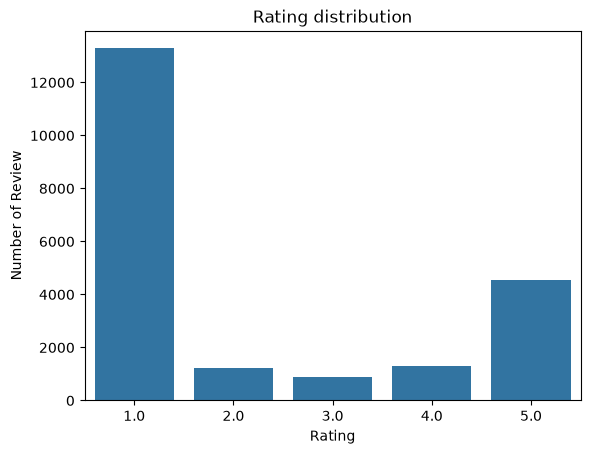

In [18]:
# Rating Distribution
sns.countplot( x= "Rating", data=data)
plt.title("Rating distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Review")

Text(0, 0.5, 'Frequency')

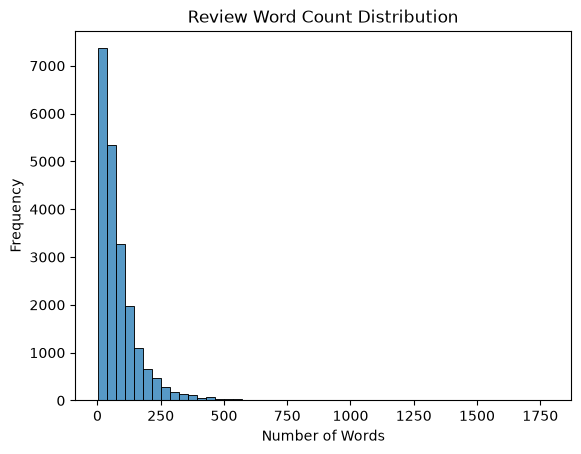

In [19]:
# Review length distribution
sns.histplot(data["Review_word_count"],bins = 50)
plt.title("Review Word Count Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

Text(0, 0.5, 'Review word count')

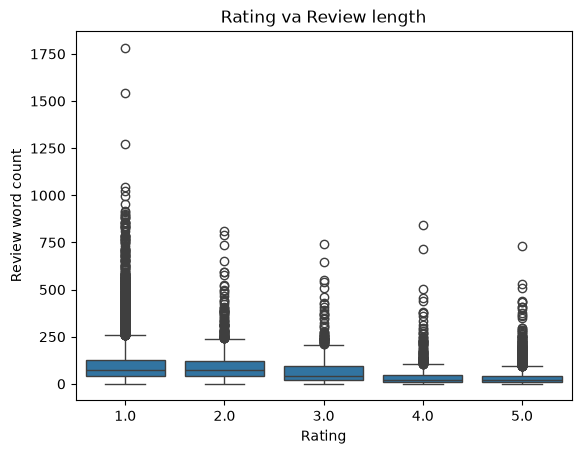

In [20]:
# Rating Vs Review length
sns.boxplot( x="Rating", y="Review_word_count", data=data)
plt.title("Rating va Review length")
plt.xlabel("Rating")
plt.ylabel("Review word count")

Text(0, 0.5, 'Number of Review')

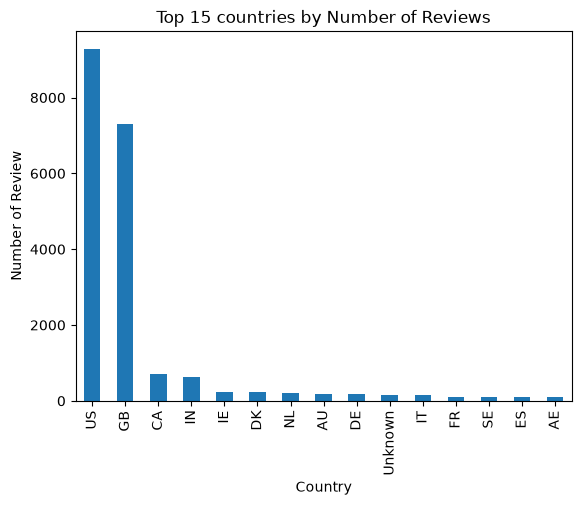

In [21]:
# Country Analysis
top_countries = data["Country"].value_counts().head(15)

top_countries.plot(kind="bar")
plt.title("Top 15 countries by Number of Reviews")
plt.xlabel("Country")
plt.ylabel("Number of Review")
        

In [22]:
# Create duplicate indicator

data["Duplicate_Review"] = ( data["Review Text"].duplicated(keep= False).astype(int))

In [23]:
# Create suspicious feature

data["Exclamation_Count"] = (data["Review Text"].str.count("!"))

In [24]:
# Create suspicious score

data["Suspicious_Score"] = (
    data["Duplicate_Review"] 
    + (data["Review_word_count"] < 5).astype(int)
    + (data["Exclamation_Count"] >= 3).astype(int)
    + (data["Review Count"] >= 100).astype(int)
    + (data["Experience_Review_Gap"] <= 1). astype(int)
)

In [25]:
# Create Suspicious / Fake Review column

data["Suspicious_Review"] = ( data["Suspicious_Score"] >= 2 ).astype(int)

In [26]:
data["Suspicious_Review"].value_counts()

Suspicious_Review
0    18185
1     3027
Name: count, dtype: int64

# Standardize the target

In [27]:
data["Review_Type"] = data["Suspicious_Review"].map({
    0: "Genuine",
    1: "Suspicious"
})
data["Review_Type"].value_counts()

Review_Type
Genuine       18185
Suspicious     3027
Name: count, dtype: int64

# Clean review text

In [28]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()

    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    text = re.sub(r"<.*?>", "", text)

    text = re.sub(r"\d+", "", text)

    text = text.translate( str.maketrans("","",string.punctuation))

    words = text.split()

    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return " ".join(words)

data["Clean_Review_Text"] = (data["Review Text"].apply(clean_text))

In [29]:
# Remove empty review

data = data[data["Clean_Review_Text"].str.strip() != ""].copy()

# Feature Selection

In [30]:
x_text = data["Clean_Review_Text"]
numeric_features = ["Rating","Review Count","Review_Length","Review_word_count","Review_Title_Length","Title_word_count",
                    "Duplicate_Review","Exclamation_Count","Experience_Review_Gap"]
x_numeric = data[numeric_features]
x_numeric = x_numeric.fillna(x_numeric.median())

In [31]:
# Select target
y = data["Suspicious_Review"]

# Train - Test Split

In [32]:
from sklearn.model_selection import train_test_split

X_text_train, X_text_test, X_numeric_train, X_numeric_test, Y_train, Y_test = train_test_split(
    x_text, x_numeric, y, test_size = 0.20, random_state = 42, stratify = y)

# TF - IDF for review text 

In [33]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer( max_features = 5000, ngram_range = (1,2), min_df = 2)

X_text_train_tfidf = tfidf.fit_transform( X_text_train)
X_text_test_tfidf = tfidf.transform( X_text_test)

print("Training text shape:", X_text_train_tfidf.shape)
print("Testing text shape:", X_text_test_tfidf.shape)

Training text shape: (16969, 5000)
Testing text shape: (4243, 5000)


In [34]:
# Scale numerical features 

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_numeric_train_scaled = scaler.fit_transform( X_numeric_train)
X_numeric_test_scaled = scaler.transform( X_numeric_test)

In [35]:
# Combine text and numerical features 

from scipy.sparse import hstack
X_train_final = hstack([ X_text_train_tfidf, X_numeric_train_scaled])
X_test_final = hstack([ X_text_test_tfidf, X_numeric_test_scaled])

print("Final training shape:", X_train_final.shape)
print("Final testing shape:", X_test_final.shape)

Final training shape: (16969, 5009)
Final testing shape: (4243, 5009)


# Logistic Regression 

In [36]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000, class_weight = "balanced")

lr.fit(X_train_final, Y_train)


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Defaul

# Prediction 

In [37]:
y_pred = lr.predict(X_test_final)
print("y_pred:", y_pred)

y_pred: [0 1 0 ... 0 0 0]


# Accuracy

In [38]:
from sklearn.metrics import accuracy_score 

accuracy = accuracy_score( Y_test, y_pred)
print("Accuracy:", round(accuracy,4))

Accuracy: 0.9456


# Complete classification report

In [39]:
from sklearn.metrics import classification_report

print(classification_report(Y_test, y_pred, target_names=["Genuine","suspicious"]))
    

              precision    recall  f1-score   support

     Genuine       0.98      0.95      0.97      3638
  suspicious       0.76      0.90      0.83       605

    accuracy                           0.95      4243
   macro avg       0.87      0.93      0.90      4243
weighted avg       0.95      0.95      0.95      4243



# Confusion matrix

Text(0.5, 1.0, 'Confusion Matrix - Logistic Regression')

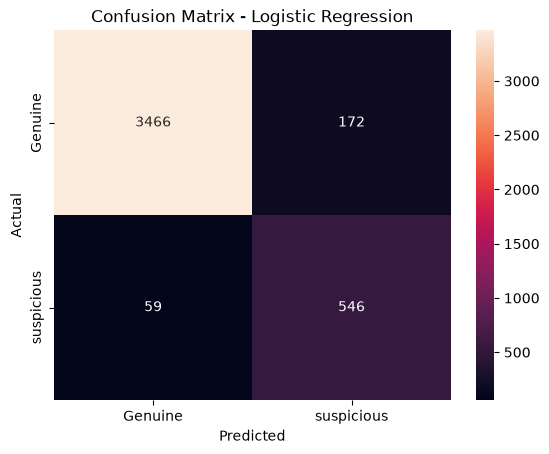

In [40]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix( Y_test, y_pred)

sns.heatmap(cm, annot= True, fmt="d", xticklabels=["Genuine","suspicious"],yticklabels=["Genuine","suspicious"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")

# SVM

In [41]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC( class_weight="balanced")
svm_model.fit(X_train_final, Y_train)

# Prediction
y_pred_svm = svm_model.predict(X_test_final)
print("y_pred_svm:", y_pred_svm)

print( classification_report( Y_test, y_pred_svm, target_names =["Genuine","suspicious"]))

y_pred_svm: [0 1 0 ... 0 0 0]
              precision    recall  f1-score   support

     Genuine       0.96      0.95      0.95      3638
  suspicious       0.70      0.76      0.73       605

    accuracy                           0.92      4243
   macro avg       0.83      0.86      0.84      4243
weighted avg       0.92      0.92      0.92      4243



# Compare Logistic Regression and SVM 

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.945557   0.760446  0.902479  0.825397
1           Linear SVM  0.920339   0.703196  0.763636  0.732171


(array([0, 1]), [Text(0, 0, 'Logistic Regression'), Text(1, 0, ' Linear SVM')])

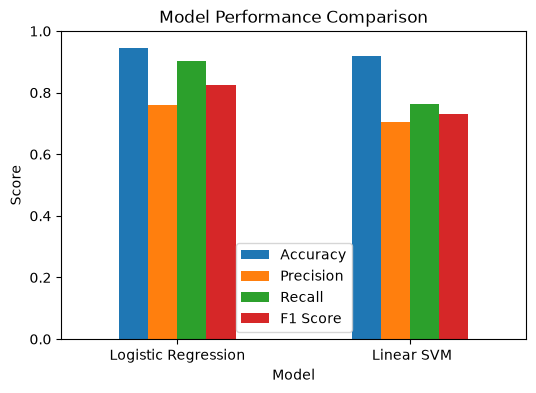

In [42]:
result = pd. DataFrame({
    "Model": ["Logistic Regression" , " Linear SVM"],
    "Accuracy": [accuracy_score(Y_test, y_pred), accuracy_score(Y_test, y_pred_svm)],
    "Precision": [precision_score(Y_test, y_pred, zero_division=0), precision_score(Y_test, y_pred_svm, zero_division=0)],
    "Recall": [recall_score(Y_test, y_pred, zero_division=0), recall_score(Y_test, y_pred_svm, zero_division=0)],
    "F1 Score": [f1_score(Y_test, y_pred, zero_division=0), f1_score(Y_test, y_pred_svm, zero_division=0)]
})
print(result)

result.set_index("Model")[["Accuracy","Precision","Recall","F1 Score"]].plot(kind="bar", figsize=(6,4))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)


# Create the prediction function 

In [43]:
def predict_review( review, rating, review_count):

    # clean text
    cleaned_review = clean_text(review)

    # TF-IDF
    text_vector = tfidf.transform([cleaned_review])

    # Calculate text features
    review_length = len(review)
    word_count = len(review.split())
    title_length = 0
    title_word_count = 0
    duplicate_review = 0 
    exclamation_count = review.count("!")
    experience_review_gap = 0

    # Numerical features
    numeric_input = pd.DataFrame([[rating,review_count,review_length,word_count,title_length,title_word_count,
                                duplicate_review,exclamation_count, experience_review_gap]], columns = numeric_features)

    numeric_scaled = scaler.transform( numeric_input )

    # Combine
    final_input = hstack([text_vector, numeric_scaled])

    # prediction
    prediction = lr.predict(final_input)[0]

    probability = lr.predict_proba(final_input)[0][1]

    if prediction == 1:
        result = "Suspicious Review"
    else:
        result = "Genuine Review"
    return result, probability

# Testing the review 

In [44]:
review = """ Amazing product ! Best product ever !!! Absolutely perfect and highly recommended !!! """
result, probability = predict_review( review, rating = 5, review_count = 160)

print("Prediction:", result)
print("Suspicious Probability:", round(probability * 100,2),"%")

Prediction: Suspicious Review
Suspicious Probability: 100.0 %


In [45]:
review = " I love the product very much"
result, probability = predict_review( review, rating = 5, review_count = 1)

print("Prediction:", result)
print("Suspicious Probability:", round(probability * 100,2),"%")

Prediction: Genuine Review
Suspicious Probability: 17.66 %


##### 

# Customer Trust Score & Analysis

In [46]:
trust_data = data.copy()

In [47]:
# Get suspicious probability for every review

trust_tfidf = tfidf.transform(trust_data["Clean_Review_Text"])

trust_numeric = trust_data[numeric_features].copy()
trust_numeric_scaled = scaler.transform(trust_numeric)

trust_final = hstack([trust_tfidf , trust_numeric_scaled])

# Calculate suspicious probability 
trust_data["Suspicious_Probability"] = ( lr.predict_proba(trust_final)[:,1])

# Geniune probability
trust_data["Genuine_Probability"] = (1 - trust_data["Suspicious_Probability"])

In [48]:
# Create review quality score

max_words = trust_data["Review_word_count"].max()

trust_data["Review_quality_score"] = (trust_data["Review_word_count"] / max_words)

In [49]:
# Create customer trust score

trust_data["Rating_Score"] = trust_data["Rating"] / 5

trust_data["Trust_Score"] = (
    0.50 * trust_data["Genuine_Probability"] 
    + 0.30 * trust_data["Rating"]
    + 0.20 * trust_data["Review_quality_score"]
)

trust_data["Trust_Score_100"] = ( trust_data["Trust_Score"]* 100)

In [50]:
# Create Trust Categories

def trust_category(score):
    if score >= 75 :
        return "High Trust"
    elif score >= 50 :
        return "Medium Trust"
    else:
        return "Low Trust"

trust_data["Trust_Category"] = ( trust_data["Trust_Score_100"].apply(trust_category))

In [51]:
trust_data["Trust_Category"].value_counts()

Trust_Category
High Trust      17467
Low Trust        2099
Medium Trust     1646
Name: count, dtype: int64

Text(0, 0.5, 'Number of reviews')

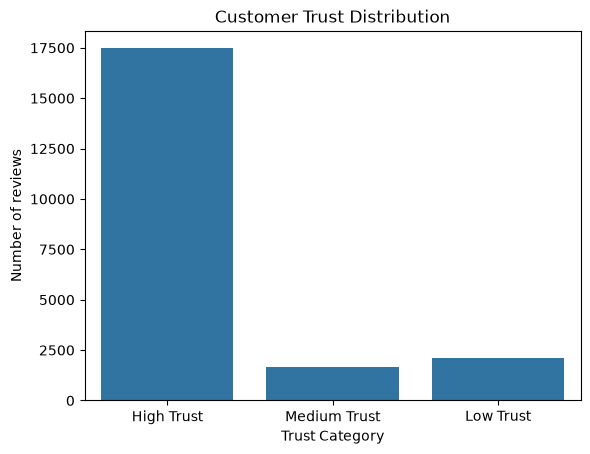

In [52]:
# Visualize customer trust

sns.countplot(x="Trust_Category", data= trust_data, order=["High Trust","Medium Trust","Low Trust"])
plt.title("Customer Trust Distribution")
plt.xlabel("Trust Category")
plt.ylabel("Number of reviews")

(array([0, 1, 2, 3, 4]),
 [Text(0, 0, '1.0'),
  Text(1, 0, '2.0'),
  Text(2, 0, '3.0'),
  Text(3, 0, '4.0'),
  Text(4, 0, '5.0')])

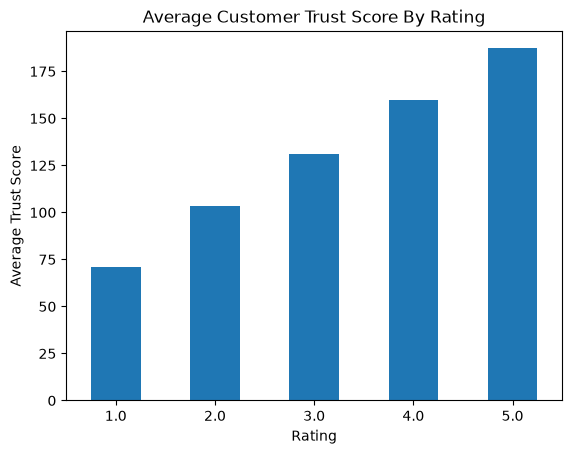

In [53]:
# Average trust score by rating 

trust_by_rating = (trust_data.groupby("Rating")["Trust_Score_100"].mean())

trust_by_rating.plot(kind="bar")
plt.title("Average Customer Trust Score By Rating")
plt.xlabel("Rating")
plt.ylabel("Average Trust Score")
plt.xticks(rotation=0)

In [54]:
# Find suspicious reviews

Suspicious_Reviews = trust_data[trust_data["Suspicious_Probability"] >= 0.70].copy()
print("Number of suspicious reviews:",len(Suspicious_Reviews))

Number of suspicious reviews: 3004


In [55]:
# Display suspicious reviews

Suspicious_Reviews[["Reviewer Name","Rating","Review Text","Suspicious_Probability","Trust_Score_100"]].sort_values("Suspicious_Probability",ascending = False).head(20)

,Reviewer Name,Rating,Review Text,Suspicious_Probability,Trust_Score_100
169,DADDY DOMINANCE GREENE,1.0,AMAZON IS A HORRIBLE ESTABLISHMENT WITH A BUNC...,1.0,34.711161
4424,Hugh Weaver,1.0,Every time my wife has a weekend delivery from...,1.0,31.233875
10231,Sungmi Kim,1.0,Stop using Purolator for delivering package fo...,1.0,31.390914
4570,Ace,1.0,Delivery was supposed to be on Tuesday. Called...,1.0,32.220976
12871,Diane LaPatra,1.0,If there was a lower rating I would use it!!! ...,1.0,32.591139
12903,Patricia Mickett Gearing,1.0,Hello all !!I have been an Amazon user for so ...,1.0,34.722378
4311,ML,1.0,Absolutely Terrible!!!!! Seems Amazon staff n...,1.0,32.478968
9752,julie silva,1.0,0 stars is more like it.. so for what ever re...,1.0,31.065620
3076,Lindsay Lee,1.0,4 of my orders not being shipped!!. I paid for...,1.0,32.310712
12814,Katy,1.0,"This company does not look at good workers, th...",1.0,31.088054


Rating
1.0    1995
2.0     128
3.0     111
4.0     147
5.0     623
dtype: int64


(array([0, 1, 2, 3, 4]),
 [Text(0, 0, '1.0'),
  Text(1, 0, '2.0'),
  Text(2, 0, '3.0'),
  Text(3, 0, '4.0'),
  Text(4, 0, '5.0')])

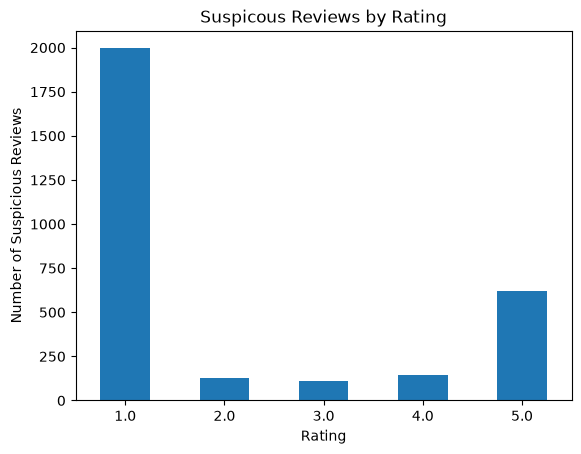

In [56]:
# Suspicious reviews by rating

suspicious_by_rating = ( Suspicious_Reviews.groupby("Rating").size().sort_index())
print(suspicious_by_rating)

suspicious_by_rating.plot(kind="bar")
plt.title("Suspicous Reviews by Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Suspicious Reviews")
plt.xticks(rotation=0)

In [57]:
# Country wise trust analysis

country_trust = (trust_data.groupby("Country").agg(Total_Reviews =("Review Text","count"), Average_Trust=("Trust_Score_100","mean"),
                Average_Suspicious_Probability=("Suspicious_Probability","mean")).sort_values("Average_Trust", ascending = False))
country_trust

,Total_Reviews,Average_Trust,Average_Suspicious_Probability
Country,,,
ET,1,198.952886,0.037095
RW,1,197.981925,0.041932
SL,1,196.794272,0.067255
SO,1,196.791234,0.068886
ZM,1,195.932485,0.085164
...,...,...,...
PG,2,55.417729,0.505442
BQ,1,42.117473,0.772681
AG,1,32.703309,1.000000


In [58]:
# Reviewer level analysis

reviewer_analysis = ( trust_data.groupby("Reviewer Name").agg(Total_Reviewes=("Review Text","count"), Average_Rating=("Rating","mean"),
                    Average_Suspicious_Probability=("Suspicious_Probability","mean"), Average_Trust_Score=("Trust_Score_100","mean")))
reviewer_analysis.sort_values("Average_Suspicious_Probability", ascending=False)

,Total_Reviewes,Average_Rating,Average_Suspicious_Probability,Average_Trust_Score
Reviewer Name,,,,
Megan Mericle,1,1.0,1.000000e+00,36.247897
Tina Brackens,1,1.0,1.000000e+00,31.357263
Philip Petre,1,1.0,1.000000e+00,31.637689
Laurie Wienholz,1,1.0,1.000000e+00,35.025238
Patricia Mickett Gearing,1,1.0,1.000000e+00,34.722378
...,...,...,...,...
Aisling McAlister,1,5.0,1.336333e-09,200.493550
Jose-Luis Reyes,1,2.0,1.925075e-11,119.119462
L.,1,5.0,4.481730e-13,201.020752


In [59]:
# Create final suspicious review report

suspicious_report = Suspicious_Reviews[["Reviewer Name","Country","Rating","Review Text","Review Count","Review_word_count",
                                       "Suspicious_Probability","Genuine_Probability","Trust_Score_100","Trust_Category"]].sort_values("Suspicious_Probability", ascending = False)

In [64]:
# Save Result

trust_data.to_csv("Customer_Trust_Analytics.csv",index= False)

suspicious_report.to_csv("Suspicious_Reviews_Report.csv", index = False)

In [65]:
from IPython.display import FileLink,display

display(FileLink("Customer_Trust_Analytics.csv"))
display(FileLink("Suspicious_Reviews_Report.csv"))

C:\Users\anush\Customer_Trust_Analytics.csv

C:\Users\anush\Suspicious_Reviews_Report.csv